In [1]:
import sys; sys.path.append("..")   # para poder importar src/
import pandas as pd
import matplotlib.pyplot as plt

m = pd.read_csv("../data/processed/matches.csv", parse_dates=["date"])
m.head()

Matplotlib is building the font cache; this may take a moment.


,match_id,date,season,home,away,home_goals,away_goals,result,odds_H,odds_D,odds_A
0,0,2017-08-11,1718,Arsenal,Leicester,4,3,H,1.51,4.43,6.44
1,1,2017-08-12,1718,Brighton,Manchester City,0,2,A,10.10,5.25,1.32
2,2,2017-08-12,1718,Chelsea,Burnley,2,3,A,1.24,6.06,13.67
3,3,2017-08-12,1718,Crystal Palace,Huddersfield,0,3,A,1.81,3.50,4.82
4,4,2017-08-12,1718,Everton,Stoke,1,0,H,1.69,3.69,5.50


result     H     D     A
season                  
1718    45.5  26.1  28.4
1819    47.6  18.7  33.7
1920    45.3  24.2  30.5
2021    37.9  21.8  40.3
2122    42.9  23.2  33.9
2223    48.4  22.9  28.7
2324    46.1  21.6  32.4
2425    40.8  24.5  34.7


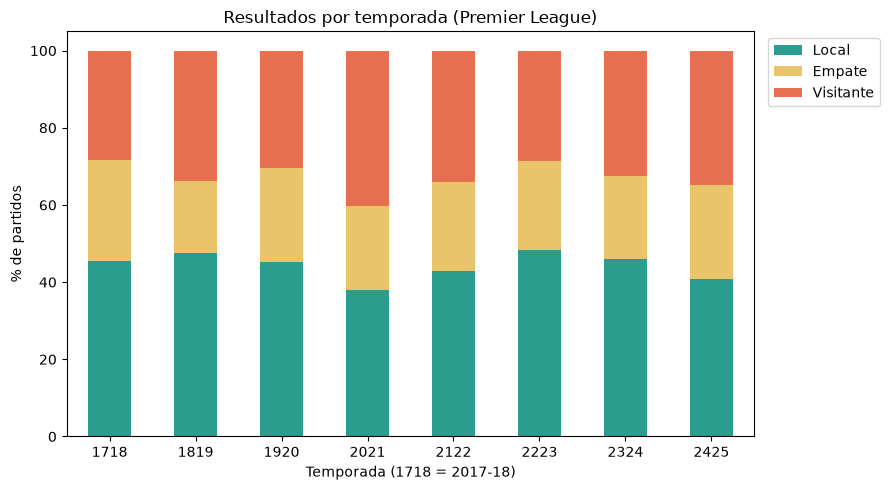

In [9]:
# Porcentaje de cada resultado por temporada
pct = (m.groupby("season")["result"]
         .value_counts(normalize=True)
         .unstack()[["H", "D", "A"]] * 100)
print(pct.round(1))

m = pd.read_csv("../data/processed/matches.csv", parse_dates=["date"])
m["season"] = m["season"].astype(str).str.zfill(4)   # 1718, 1819, ...

ax = pct.plot(kind="bar", stacked=True, figsize=(9, 5),
              color=["#2a9d8f", "#e9c46a", "#e76f51"])
ax.set_title("Resultados por temporada (Premier League)")
ax.set_xlabel("Temporada (1718 = 2017-18)")
ax.set_ylabel("% de partidos")
ax.legend(["Local", "Empate", "Visitante"], loc="upper left", bbox_to_anchor=(1.01, 1))
plt.xticks(rotation=0)
plt.tight_layout()
plt.savefig("../docs/eda_resultados_por_temporada.png", dpi=150)
plt.show()

        goles_local  goles_visitante  pct_local  dif_goles
season                                                    
1718           1.53             1.15      45.53       0.38
1819           1.57             1.25      47.63       0.32
1920           1.52             1.21      45.26       0.31
2021           1.35             1.34      37.89       0.01
2122           1.51             1.31      42.89       0.21
2223           1.63             1.22      48.42       0.42
2324           1.80             1.48      46.05       0.32
2425           1.51             1.42      40.79       0.09


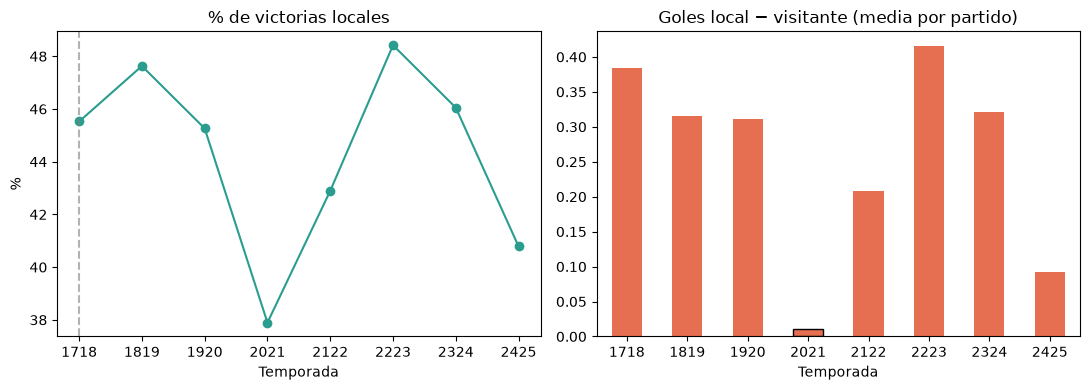

In [5]:
# Ventaja local por temporada: goles medios y % de victorias locales
by_season = m.groupby("season").agg(
    goles_local=("home_goals", "mean"),
    goles_visitante=("away_goals", "mean"),
    pct_local=("result", lambda s: (s == "H").mean() * 100),
)
by_season["dif_goles"] = by_season["goles_local"] - by_season["goles_visitante"]
print(by_season.round(2))

fig, axes = plt.subplots(1, 2, figsize=(11, 4))

by_season["pct_local"].plot(ax=axes[0], marker="o", color="#2a9d8f")
axes[0].set_title("% de victorias locales")
axes[0].set_xlabel("Temporada"); axes[0].set_ylabel("%")

by_season["dif_goles"].plot(kind="bar", ax=axes[1], color="#e76f51")
axes[1].set_title("Goles local − visitante (media por partido)")
axes[1].set_xlabel("Temporada"); axes[1].tick_params(axis="x", rotation=0)

# resalta 2020-21 en ambos gráficos
axes[0].axvline("2021", color="gray", linestyle="--", alpha=0.6)
axes[1].patches[list(by_season.index).index("2021")].set_edgecolor("black")

plt.tight_layout()
plt.savefig("../docs/eda_ventaja_local.png", dpi=150)
plt.show()

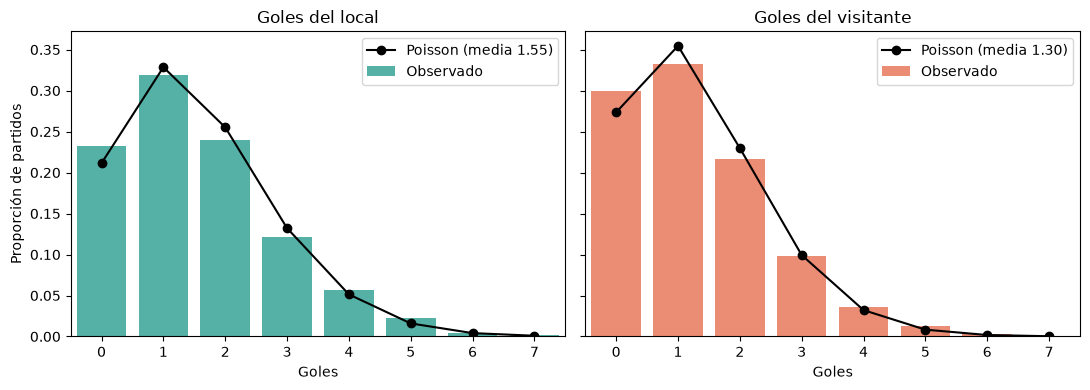

In [6]:
import numpy as np
from scipy.stats import poisson

fig, axes = plt.subplots(1, 2, figsize=(11, 4), sharey=True)
for ax, col, title, color in [
    (axes[0], "home_goals", "Goles del local", "#2a9d8f"),
    (axes[1], "away_goals", "Goles del visitante", "#e76f51"),
]:
    obs = m[col].value_counts(normalize=True).sort_index()
    k = np.arange(0, 8)
    esperado = poisson.pmf(k, m[col].mean())
    ax.bar(obs.index, obs.values, color=color, alpha=0.8, label="Observado")
    ax.plot(k, esperado, "ko-", label=f"Poisson (media {m[col].mean():.2f})")
    ax.set_title(title); ax.set_xlabel("Goles"); ax.set_xlim(-0.5, 7.5)
    ax.legend()
axes[0].set_ylabel("Proporción de partidos")

plt.tight_layout()
plt.savefig("../docs/eda_distribucion_goles.png", dpi=150)
plt.show()

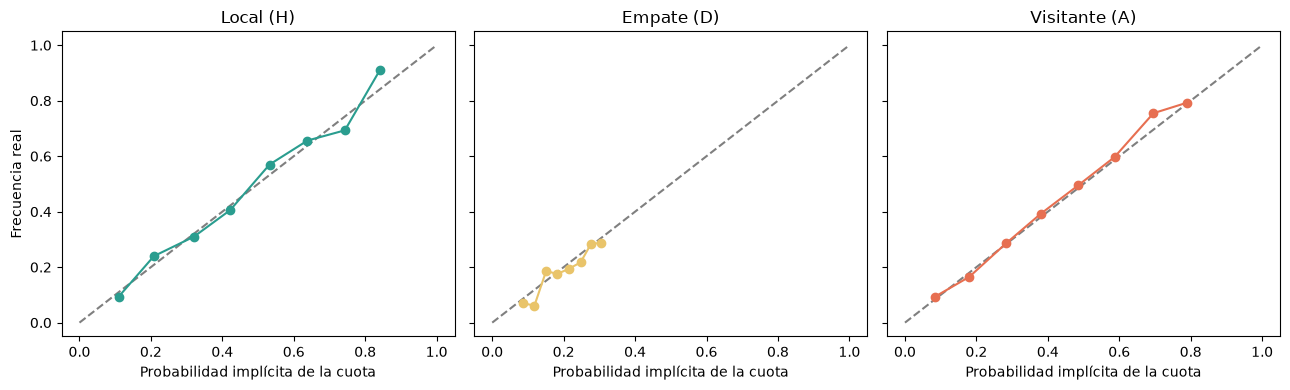

In [7]:
from src.evaluation.metrics import implied_probs

p = implied_probs(m)                      # columnas H, D, A sin margen de la casa
real = pd.get_dummies(m["result"])[["H", "D", "A"]].to_numpy()

fig, axes = plt.subplots(1, 3, figsize=(13, 4), sharey=True)
for i, (nombre, color) in enumerate([("Local (H)", "#2a9d8f"),
                                      ("Empate (D)", "#e9c46a"),
                                      ("Visitante (A)", "#e76f51")]):
    bins = pd.cut(p[:, i], bins=8)
    tabla = pd.DataFrame({"pred": p[:, i], "real": real[:, i]}).groupby(bins, observed=True).mean()
    axes[i].plot([0, 1], [0, 1], "k--", alpha=0.5)
    axes[i].plot(tabla["pred"], tabla["real"], "o-", color=color)
    axes[i].set_title(nombre); axes[i].set_xlabel("Probabilidad implícita de la cuota")
axes[0].set_ylabel("Frecuencia real")

plt.tight_layout()
plt.savefig("../docs/eda_cuotas_calibracion.png", dpi=150)
plt.show()